# Agentic RAG From Scratch: Opening Up the Agent Loop with LangGraph

In Session 3, `create_agent` gave you an agent in a handful of lines — but it hid the loop. You passed in a model, tools, and a prompt, and a working agent came out. Today we **open that black box** and build the exact same loop ourselves, by hand, with **LangGraph** — the low-level graph engine `create_agent` is built on.

```text
Session 3:  create_agent(model, tools, prompt)   ← one call, loop hidden
Session 4:  StateGraph + nodes + edges           ← you wire the loop yourself
```

Why bother, when `create_agent` already works? Because the moment you need something the abstraction doesn't offer — custom routing ("always search before quoting a price"), a node that logs or validates, a loop you can bound and inspect — you need to see the wiring. Building the loop once, from scratch, is how it stops being magic.

We'll build a **ReAct-style agent** as an explicit graph: a node that calls the model, a node that runs tools, and a conditional edge that decides whether to loop or finish. Then we'll turn it into **Agentic RAG** by giving it a retrieval tool over our wellness knowledge base — the same use case from Sessions 2 and 3, now built on primitives you control.

> 🧭 **Where this sits in the course:** Frameworkless RAG (Session 2) → The Agent Harness with `create_agent` (Session 3) → **Agentic RAG From Scratch (you are here)**. Same wellness use case throughout, so you can feel exactly what the abstraction was doing for you.

### 🏗️ Build · 🚢 Ship · 🚀 Share
- **🏗️ Build:** a ReAct agent as a LangGraph `StateGraph`, then an Agentic RAG agent with a retrieval tool — all from scratch.
- **🚢 Ship:** extend the graph with a custom routing function or conversation memory, and compare it to the `create_agent` version.
- **🚀 Share:** record a short walkthrough and post three lessons learned.

> NOTE: Built and tested with Python 3.11+. This folder is a self-contained `uv` project. We use the same cloud OpenAI models as Sessions 2–3 — no new model setup.

<a id="toy-project"></a>
## 🧘 The toy project: a Pocket Wellness Coach (now with two sources)

We're building the same **Pocket Wellness Coach** from Session 3 — for the member **Sam** — but this time the loop is *yours*, wired by hand with LangGraph. Sam's day sends different questions to different places, and now there are **two** knowledge sources, not one:

| Sam asks… | The coach should… | Which tool |
| --- | --- | --- |
| "What stretches help my lower-back pain?" | look it up in the **local guide** | `search_wellness_knowledge` (Qdrant) |
| "How much water should I drink at 80 kg?" | do the math — *not* search | `hydration_calculator` |
| "What time is it — is it wind-down o'clock?" | check the clock | `get_current_time` |
| "Any *recent* research on magnesium for sleep?" | the guide can't know — search the **web** | `web_search` (Tavily, optional) |
| "Who won the 2022 World Cup?" | just answer — out of its lane | *(no tool)* |

Two sources is the whole reason to build the loop by hand: *try the guide first? cap web calls? never cite an unvetted web result?* Those are **routing decisions you own** in a graph — not something to leave to the model's goodwill. That's the thread of this session.

> The local guide is the course's `HealthWellnessGuide.txt`; `web_search` turns on only if you add a `TAVILY_API_KEY` (free tier) to `.env`. Without it, the coach runs happily on the guide alone.

## 🎯 By the End of This Session

By the end of this notebook you'll have rebuilt the agent loop from Session 3 using LangGraph primitives — and you'll understand what `create_agent` was doing the whole time. Specifically, you'll be able to:

- **Explain LangGraph's model** — describe **state**, **nodes**, and **edges**, and how a graph passes state from node to node.
- **Build the ReAct loop by hand** — wire an `agent` node, a `tools` node, and a **conditional edge** that routes between "call a tool" and "finish."
- **Bind tools to a model** — use `.bind_tools()` so the model can *request* tool calls, and run them with a prebuilt `ToolNode`.
- **Control the routing** — write the `should_continue` function that is the actual decision `create_agent` hid from you.
- **Build Agentic RAG from scratch** — index the wellness guide into Qdrant, wrap the retriever as a tool, and drop it into your own graph.
- **Inspect & visualize the graph** — stream node-by-node updates and render the compiled graph so the loop is concrete.
- **Reason about convenience vs. control** — know when to reach for `create_agent` and when to drop down to LangGraph.

## 📜 Table of Contents

- [🧘 The toy project: Pocket Wellness Coach](#toy-project)
- [🏃 How to Run This Notebook](#how-to-run)
- [🧑‍💻 Setup](#setup)
- [🏗️ By the End of the Sesh (the finished graph, first)](#by-the-end)
- 🤜 **Breakout Room #1**
  - [✅ Task 1: LangGraph 101 — State, Nodes, Edges](#task-1)
  - [✅ Task 2: Build the ReAct Loop From Scratch](#task-2)
  - [✅ Task 3: Run & Inspect the Loop](#task-3)
- 🤜 **Breakout Room #2**
  - [✅ Task 4: Index the Knowledge Base (LangChain + Qdrant)](#task-4)
  - [✅ Task 5: Assemble Agentic RAG From Scratch](#task-5)
- [🏗️ By the End of the Sesh (recap)](#recap)
- [💼 Business Case Study](#business-case)
- [🏭 What We Built vs. What's in Production](#production)
- [👋 Conclusion](#conclusion)
- [📖 Official Documentation](#docs)

<a id="how-to-run"></a>
## 🏃 How to Run This Notebook

This folder is a self-contained [`uv`](https://docs.astral.sh/uv/) project. From inside `04_Agentic_Search/`:

1. **Install `uv`** if you don't have it — see the [Initial Setup guide](../00_Docs/Prerequisites/Initial_Setup/README.md).
2. **Sync dependencies:** `uv sync` (installs LangGraph, LangChain 1.0, `langchain-openai`, `langchain-qdrant`, `qdrant-client`, and friends).
3. **Add your OpenAI key:** create a `.env` in this folder with `OPENAI_API_KEY=sk-...`. The Setup cell calls `load_dotenv()` for you; if no `.env` is found it will prompt you once.
4. **Open this notebook and select the `.venv` kernel.**
5. **Run the cells top to bottom.** `nest_asyncio` (enabled in Setup) lets async calls run inside Jupyter.

> 💡 This session uses the same cloud models as Session 3 (`gpt-5.6-sol` + `text-embedding-3-small`). The focus is the **graph you build**, not the model behind it.

<a id="setup"></a>
## 🧑‍💻 Setup

Keep this short — imports and keys only. We want to get straight into the graph.

In [1]:
import sys
print(sys.executable)

/Users/ccustis/Documents/aimakerspace/AIE11/04_Agentic_Search/.venv/bin/python


In [22]:
import os
import getpass
from typing import Annotated, Literal, TypedDict

import nest_asyncio
from dotenv import load_dotenv

nest_asyncio.apply()  # let async calls run inside Jupyter

# Load OPENAI_API_KEY from a .env file in this folder.
# If there's no .env yet, ask for the key once, interactively.
load_dotenv()
if not os.environ.get("OPENAI_API_KEY"):
    os.environ["OPENAI_API_KEY"] = getpass.getpass("OpenAI API Key: ")

# gpt-5.6-sol: max-capability model with strong tool-calling.
# (gpt-5.6-luna/terra are reasoning-only and can't tool-call over chat completions.)
# Swap in a lighter model like "gpt-5.4-mini" if you want faster, cheaper runs.
AGENT_MODEL = "gpt-5.6-sol"
EMBED_MODEL = "text-embedding-3-small"
print(f"Chat model: {AGENT_MODEL}  |  Embeddings: {EMBED_MODEL}")

# A tiny display helper, reused wherever we show the model's prose answer: render
# it as Markdown (bullets, bold, headings) instead of raw text with literal "*".
from IPython.display import Markdown, display


def show_answer(text):
    if isinstance(text, list):
        text = "\n\n".join(
            block["text"]
            for block in text
            if isinstance(block, dict) and block.get("type") == "text"
        )
    display(Markdown(text))

Chat model: gpt-5.6-sol  |  Embeddings: text-embedding-3-small


<a id="langsmith"></a>
#### (Optional) Turn on LangSmith tracing

LangSmith records every model and tool step and draws the whole graph — the `agent` node, each `ToolNode` call, every loop back through `should_continue` — as a visual trace. It's the easiest way to *see* the loop you're about to build. LangGraph traces itself automatically once it's on, so there are **no `@traceable` decorators to add** anywhere in this notebook.

**Easiest way to enable it:** uncomment the three `LANGSMITH_*` lines in your `.env` (they're in `.env.example`) and drop in a key from [smith.langchain.com](https://smith.langchain.com) (free to start). `load_dotenv()` in Setup already picked them up — nothing else to change. Prefer to keep it off? Leave them commented; everything runs the same. The cell below is just an in-notebook alternative if you'd rather flip it on from here.

In [3]:
from dotenv import load_dotenv

load_dotenv(override=True)

True

In [4]:
import os

print("Tracing enabled:", os.getenv("LANGSMITH_TRACING"))
print("API key configured:", bool(os.getenv("LANGSMITH_API_KEY")))

Tracing enabled: true
API key configured: True


In [5]:
# Tracing is best enabled in .env — uncomment the LANGSMITH_* lines there and
# re-run the Setup cell above (load_dotenv picks them up, no code changes needed).
#
# If you'd rather flip it on from the notebook instead, uncomment these three:
# os.environ["LANGSMITH_TRACING"] = "true"
# os.environ["LANGSMITH_API_KEY"] = getpass.getpass("LangSmith API Key: ")
# os.environ["LANGSMITH_PROJECT"] = "aie-agentic-rag"

<a id="task-1"></a>
## ✅ Task 1: LangGraph 101 — State, Nodes, Edges

<div align="center">
<img src="images/task-1.svg" alt="LangGraph 101 — state, nodes, edges" width="760">
</div>


A LangGraph app is a **graph** you move **state** through. Three ideas, that's all:

- **State** — a shared dictionary (a `TypedDict`) that every node reads and updates. Ours holds a list of `messages`.
- **Nodes** — plain Python functions. Each takes the state, does something, and returns an update to it.
- **Edges** — the wiring that says which node runs next. A **conditional edge** picks the next node based on the state.

> 🔑 `create_agent` compiled a graph exactly like this for you. We'll warm up with the simplest possible one — an **echo graph** with a single node — then build the real agent loop in Task 2.

The special piece is `add_messages`: it's a **reducer** that tells LangGraph to *append* new messages to the list instead of overwriting it. That's what lets the conversation accumulate as the graph loops.

In [6]:
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages
from langchain_core.messages import HumanMessage, AIMessage


# 1) State: a dict whose "messages" list is appended to (not replaced) on each update.
class SimpleState(TypedDict):
    messages: Annotated[list, add_messages]


# 2) Node: a function that reads state and returns an update.
def echo_node(state: SimpleState):
    last = state["messages"][-1]
    return {"messages": [AIMessage(content=f"You said: {last.content}")]}


# 3) Graph: wire START -> echo -> END, then compile.
echo_graph = StateGraph(SimpleState)
echo_graph.add_node("echo", echo_node)
echo_graph.add_edge(START, "echo")
echo_graph.add_edge("echo", END)
echo_app = echo_graph.compile()

result = echo_app.invoke({"messages": [HumanMessage(content="Hello, LangGraph!")]})
for msg in result["messages"]:
    print(f"[{type(msg).__name__}] {msg.content}")

[HumanMessage] Hello, LangGraph!
[AIMessage] You said: Hello, LangGraph!


<a id="task-2"></a>
## ✅ Task 2: Build the ReAct Loop From Scratch

The pattern we're building is **ReAct** — *Reasoning + Acting* — introduced by [Yao et al., 2022](https://arxiv.org/abs/2210.03629). The agent **reasons** about what it needs, **acts** by calling a tool, **observes** the result, and repeats until it can answer:

<div align="center">
<img src="images/react-cycle.svg" alt="The ReAct loop: Reason, Act, Observe, repeat — over the agent's tools" width="760">
</div>

As a LangGraph, that same loop is just two nodes and one decision — a node that calls the model, a node that runs tools, and a conditional edge that routes between them:

<div align="center">
<img src="images/task-2.svg" alt="The ReAct loop, built from scratch" width="760">
</div>

We'll build it in four small steps.

### Step 1 — State, model, and tools
The agent's state is a growing list of messages. We initialize the model and **bind** our tools to it — `.bind_tools()` is what lets the model *request* a tool call (it doesn't run anything itself; it just asks).

In [7]:
from langchain_core.messages import BaseMessage, SystemMessage, ToolMessage
from langchain_core.tools import tool
from langchain_openai import ChatOpenAI
from langgraph.prebuilt import ToolNode


class AgentState(TypedDict):
    """The agent's whole memory: a list of messages, appended to as it loops."""
    messages: Annotated[list[BaseMessage], add_messages]


@tool
def hydration_calculator(weight_kg: float, activity_minutes: int = 0) -> str:
    """Estimate a personalized daily water target (glasses + ounces).

    Use this for "how much water should I drink" questions. Do NOT use it to
    look up wellness advice — that's the knowledge base's job.

    Args:
        weight_kg: body weight in kilograms.
        activity_minutes: minutes of exercise planned today (optional).
    """
    ml = 35 * weight_kg + (activity_minutes / 30) * 350  # ~35 ml/kg, +350 ml per 30 min active
    ounces = ml / 29.5735
    glasses = ounces / 8
    return (
        f"About {ounces:.0f} oz (~{glasses:.1f} glasses of water) today. "
        f"The guide's baseline is 8 glasses / 64 oz, scaled for your body size and activity."
    )


@tool
def get_current_time() -> str:
    """Get the current date and time. Use this when the user asks what time or date it is."""
    from datetime import datetime

    return f"The current date and time is: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}"


tools = [hydration_calculator, get_current_time]
llm = ChatOpenAI(model=AGENT_MODEL, temperature=0)
llm_with_tools = llm.bind_tools(tools)  # tell the model what tools exist
print("Model bound to tools:", [t.name for t in tools])

Model bound to tools: ['hydration_calculator', 'get_current_time']


### Step 2 — The agent node
A node is just a function. This one prepends a system prompt, calls the tool-aware model, and returns the model's message to be appended to state.

In [8]:
SYSTEM_PROMPT = (
    "You are a helpful assistant that can do math and tell the time. "
    "Use a tool when it helps; otherwise just answer. Be concise."
)


def agent_node(state: AgentState):
    """Call the model with the running conversation; return its reply."""
    messages = [SystemMessage(content=SYSTEM_PROMPT)] + state["messages"]
    response = llm_with_tools.invoke(messages)
    return {"messages": [response]}


print("agent_node defined")

agent_node defined


### Step 3 — The tool node and the router
`ToolNode` is a prebuilt node that runs whatever tools the model asked for. The **router** — `should_continue` — is the single decision at the heart of every agent: *did the model request a tool, or is it done?* This function is exactly what `create_agent` wrote for you behind the scenes.

In [9]:
# The tool node: executes the tool calls the model requested.
tool_node = ToolNode(tools)


def should_continue(state: AgentState) -> Literal["tools", "end"]:
    """Route to the tools node if the model requested a tool; otherwise finish."""
    last_message = state["messages"][-1]
    if getattr(last_message, "tool_calls", None):
        return "tools"
    return "end"


print("tool_node + should_continue defined")

tool_node + should_continue defined


### Step 4 — Wire the graph
Now we connect the pieces: start at `agent`, branch with `should_continue`, and send `tools` back to `agent` so the loop can continue. **This is the block from the top of the notebook.**

In [10]:
workflow = StateGraph(AgentState)

workflow.add_node("agent", agent_node)
workflow.add_node("tools", tool_node)

workflow.add_edge(START, "agent")
workflow.add_conditional_edges(
    "agent",
    should_continue,
    {"tools": "tools", "end": END},  # map the router's return value to the next node
)
workflow.add_edge("tools", "agent")  # the loop: after tools, think again

agent = workflow.compile()
print("ReAct agent built from scratch!")

ReAct agent built from scratch!


<a id="question-1"></a>
#### ❓ Question #1

Our `should_continue` function returns `"tools"` or `"end"`. What is `create_agent` from Session 3 doing in place of this function — and what did writing it yourself reveal about the agent loop?

> NOTE: Think about *who* decides to keep looping, and what information that decision is based on.


`create_agent` automatically handles the routing that `should_continue` makes explicit. It checks whether the model requested a tool, executes it, and loops back until no tool calls remain. Writing this ourselves revealed that the model decides when tools are needed, while the graph controls how those decisions are executed.

<a id="task-3"></a>
## ✅ Task 3: Run & Inspect the Loop

<div align="center">
<img src="images/task-3.svg" alt="Run &amp; inspect — nothing is hidden" width="760">
</div>


Because *we* built the graph, nothing is hidden. We'll run it, stream it node-by-node, and render it.

### Invoke it
Watch the message list grow: your question, the model's tool request, the tool result, then the final answer.

In [11]:
response = agent.invoke({"messages": [HumanMessage(content="How much water should I drink at 80 kg?")]})

print("Message trail:")
for msg in response["messages"]:
    kind = type(msg).__name__
    if getattr(msg, "tool_calls", None):
        print(f"  [{kind}] -> requests: {[tc['name'] for tc in msg.tool_calls]}")
    else:
        print(f"  [{kind}] {msg.content[:120]}")

Message trail:
  [HumanMessage] How much water should I drink at 80 kg?
  [AIMessage] -> requests: ['hydration_calculator']
  [ToolMessage] About 95 oz (~11.8 glasses of water) today. The guide's baseline is 8 glasses / 64 oz, scaled for your body size and act
  [AIMessage] [{'type': 'text', 'text': 'At **80 kg**, aim for about **95 oz (2.8 L)** of water daily—roughly **12 eight-ounce glasses**. You may need more with exercise, heat, pregnancy, or illness.', 'annotations': [], 'id': 'msg_0e5b5af9675c37eb006afdcc4a293487d2bb9007d13cd74dbc', 'phase': 'final_answer'}]


### Stream the loop
Streaming with `stream_mode="updates"` prints each node as it fires — you literally watch the graph walk `agent → tools → agent → END`.

In [12]:
print("Streaming agent execution:")
for chunk in agent.stream(
    {"messages": [HumanMessage(content="How much water should I drink if I exercise 45 minutes at 70 kg?")]},
    stream_mode="updates",
):
    for node_name, update in chunk.items():
        print(f"\n[node: {node_name}]")
        for msg in update.get("messages", []):
            if getattr(msg, "tool_calls", None):
                print(f"  tool calls: {[tc['name'] for tc in msg.tool_calls]}")
            elif msg.content:
                print(f"  content: {msg.content[:150]}")

Streaming agent execution:

[node: agent]
  tool calls: ['hydration_calculator']

[node: tools]
  content: About 101 oz (~12.6 glasses of water) today. The guide's baseline is 8 glasses / 64 oz, scaled for your body size and activity.

[node: agent]
  content: [{'id': 'rs_050c2a28cdb961ef006afdcc60771887d28168eccba2dec120', 'summary': [], 'type': 'reasoning', 'content': [], 'encrypted_content': 'gAAAAABq_cxhr1uR2BlxyDwTYc8XAuawZXG_O3YPx2hLyWmpHNa3A9kgqvePpAloeafGSZcX_as53GIzqUNA8Yz6xKIozptNjZ2RjKz2gOonGgbV-aiBHBpKnhTQX4-IslDMCQY0-arwy7VogPg-vnAfny3DAEgeSUz7S_LyezjE75-rh3zFBrfJd9gZLU2Qdr0fRfQYtdR_0U4_VtmvR-Cu6sXvJmk4bRZAdpByaUSHVYoTsIsLQdRxhx48d432o7umRo6kVluc6twPgNhIFbCxMATykj2S2yY20cEE9unUydkB5H0lzEf2MDa10N3EDWWjxWd78IHPcKzvIw9Dp37WBG9dH7LA0x8wprQW4EFWTe_Kqhhl8HscM3IASsUWjzcTXg90gIH8yLWNqCNwzZwMxm61kjecZiRIi2GQAcj3HtncMNB7CMk2ZnmYeBnqxJzEK-moCZPDnp1oFqpWfo54k3ITqJJ7T8wnrSIPA-g9Lq8i44wikNIsWYd-_d4eCo-nJ0jt_y9G-PwLLoMIALNO7xuFUsfIW8_G2pooIlY7sL2aMVuEl-rpYPdVlUxqU92KuTfXDP1tdz0Y6byoW_IXg

### Visualize the graph
The compiled graph can draw itself. This is the same picture `create_agent` produced in Session 3 — but now you can point to every node and edge and say what it does.

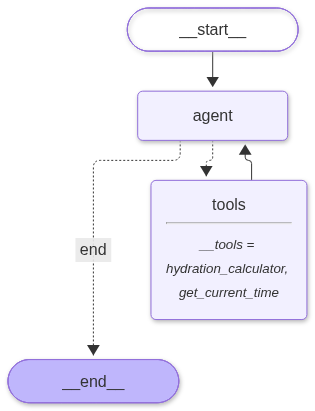

In [13]:
try:
    from IPython.display import Image, display

    display(Image(agent.get_graph().draw_mermaid_png()))
except Exception as e:
    print(f"(PNG unavailable: {e})\n")
    print(agent.get_graph().draw_ascii())

<a id="question-2"></a>
#### ❓ Question #2

In Session 3, middleware hooked into the loop to log steps and cap model calls. Looking at *this* graph, where would you add logging, or enforce a limit on how many times the loop can run? What does that tell you about what middleware really was?

> NOTE: Every hook point in `create_agent` corresponds to something concrete here — a node, an edge, or the router.


I would add logging at the agent and tool nodes to capture each step, and enforce a loop limit in `should_continue` by tracking iterations. This reveals that middleware is essentially logic inserted at specific points in the graph to monitor, control, or modify agent behavior.

> 🧑‍🤝‍🧑 **Breakout Room #1.** Trace one streamed run out loud as a group: name each node as it fires and what `should_continue` returned. Then find the exact line where you'd insert a step counter to stop a runaway loop.

<a id="task-4"></a>
## ✅ Task 4: Index the Knowledge Base (LangChain + Qdrant)

<div align="center">
<img src="images/task-4.svg" alt="Index the knowledge base → a retrieval tool" width="760">
</div>


Time to make it *Agentic RAG*. We reuse the same **Health & Wellness Guide** from Sessions 2–3, but now we load and index it with the **LangChain ecosystem** instead of the hand-rolled `aimakerspace` utilities.

### Step 1 — Load & chunk with LangChain
`TextLoader` reads the file into `Document` objects; `RecursiveCharacterTextSplitter` splits smartly — it tries to keep paragraphs together, then sentences, then words, instead of cutting blindly at a fixed length.

In [23]:
from langchain_community.document_loaders import TextLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter

loader = TextLoader("data/HealthWellnessGuide.txt")
documents = loader.load()

text_splitter = RecursiveCharacterTextSplitter(
    chunk_size=500,
    chunk_overlap=100,
    length_function=len,
    # default separators try ["\n\n", "\n", " ", ""] in order
)
chunks = text_splitter.split_documents(documents)

print(f"Loaded {len(documents)} document(s), split into {len(chunks)} chunks")
print("-" * 50)
print(chunks[0].page_content[:300] + "...")

Loaded 1 document(s), split into 45 chunks
--------------------------------------------------
The Personal Wellness Guide
A Comprehensive Resource for Health and Well-being

PART 1: EXERCISE AND MOVEMENT

Chapter 1: Understanding Exercise Basics

Exercise is one of the most important things you can do for your health. Regular physical activity can improve your brain health, help manage weigh...


### Step 2 — Embed & store in Qdrant (on disk)
We embed each chunk with `text-embedding-3-small` and store the vectors in a **persistent, on-disk** Qdrant collection. Qdrant memory-maps its files to disk by default, so the collection **survives a kernel restart** — we embed **once**, and every run after that reloads from disk instead of paying to embed again. Pointing the same code at a hosted Qdrant server is a one-line client swap; that's the production path.

> 💡 On-disk Qdrant locks its storage folder to a single client. If a re-run raises *"already accessed by another instance,"* restart the kernel — your vectors are safe on disk.

In [15]:
from langchain_openai import OpenAIEmbeddings
from langchain_qdrant import QdrantVectorStore
from qdrant_client import QdrantClient
from qdrant_client.http.models import Distance, VectorParams

embedding_model = OpenAIEmbeddings(model=EMBED_MODEL)
embedding_dim = len(embedding_model.embed_query("test"))

# On-disk Qdrant: vectors persist to memory-mapped files, so they survive a kernel
# restart. Embed once; later runs load from disk instead of paying to re-embed.
QDRANT_PATH = "qdrant_storage"
collection_name = "wellness_knowledge_base"

# The on-disk client locks its folder to one handle — release a previous one on re-run.
_prev_client = globals().get("qdrant_client")
if _prev_client is not None:
    _prev_client.close()
qdrant_client = QdrantClient(path=QDRANT_PATH)
# Hosted/shared instead? Run a Qdrant server, then swap the line above for: QdrantClient(url="http://localhost:6333")

if not qdrant_client.collection_exists(collection_name):
    qdrant_client.create_collection(
        collection_name=collection_name,
        vectors_config=VectorParams(size=embedding_dim, distance=Distance.COSINE),
    )

vector_store = QdrantVectorStore(
    client=qdrant_client,
    collection_name=collection_name,
    embedding=embedding_model,
)

# Only embed when the collection is empty — otherwise reuse what's already on disk.
if qdrant_client.count(collection_name).count == 0:
    vector_store.add_documents(chunks)
    print(f"Embedded and stored {len(chunks)} chunks in '{collection_name}'")
else:
    print(f"Loaded existing '{collection_name}' from disk — skipped re-embedding")

retriever = vector_store.as_retriever(search_kwargs={"k": 3})
print(f"Retriever ready (dim={embedding_dim}, path='{QDRANT_PATH}/')")

Embedded and stored 45 chunks in 'wellness_knowledge_base'
Retriever ready (dim=1536, path='qdrant_storage/')


### Step 3 — Wrap the retriever as a tool
This is the line that makes RAG *agentic*: the retriever becomes a tool, and its docstring tells the model **when** to reach for it. The agent — not your control flow — decides whether to retrieve.

In [16]:
@tool
def search_wellness_knowledge(query: str) -> str:
    """Search the wellness knowledge base for health, fitness, nutrition, sleep, and mental-wellness info.

    Use this whenever the user asks a wellness question (exercise, diet, sleep, stress, healthy habits).
    Do NOT use it for math, the time, or general trivia.

    Args:
        query: What to look up in the wellness guide.
    """
    results = retriever.invoke(query)
    if not results:
        return "No relevant information found in the wellness knowledge base."
    return "\n\n".join(f"[Source {i}]:\n{doc.page_content}" for i, doc in enumerate(results, 1))


print("RAG tool ready:", search_wellness_knowledge.name)
print(search_wellness_knowledge.invoke({"query": "how can I improve my sleep?"})[:300] + "...")

RAG tool ready: search_wellness_knowledge
[Source 1]:
Chapter 8: Improving Sleep Quality

Sleep hygiene refers to habits and practices that promote consistent, quality sleep.

Essential sleep hygiene practices:
- Maintain a consistent sleep schedule, even on weekends
- Create a relaxing bedtime routine (reading, gentle stretching, warm bath...


<a id="task-5"></a>
## ✅ Task 5: Assemble Agentic RAG From Scratch

<div align="center">
<img src="images/task-5.svg" alt="Agentic RAG from scratch: two sources, your routing" width="760">
</div>


Here's the payoff: we reuse the **exact same graph structure** from Task 2 — `agent` node, `tools` node, `should_continue` router — and just swap in the wellness tools and a wellness prompt. That's the power of building on primitives: the loop is reusable; only the tools and prompt change.

### Step 1 — A wellness agent node
Same shape as `agent_node`, new system prompt, and the RAG tool added to the toolbox.

### Why build this by hand? Two sources, one routing decision

The agent is about to get a second place to look: besides the **local guide** (`search_wellness_knowledge`), we add an optional **web search** (`web_search`, via Tavily). Two sources raise control questions a plain `create_agent` loop leaves to the model's goodwill:

- *Try the local guide first, and only hit the web when it misses?*
- *Cap web calls to one per question — they cost money and add latency?*
- *Never let a medical claim come from an unvetted web result?*

These are **routing and policy** decisions, and they live in the graph. Because *you* own the nodes and edges, you can add a router that sends guide questions one way and current-events questions another, require a local search before a web search, or count web calls in the state and stop at a budget. In `create_agent` you'd reach for middleware and hope the model cooperates; here the decision is **explicit and yours**. That is the payoff of building the loop by hand — and exactly the kind of control [Technical Challenge 2](../00_Technical_Challenges/Week%202/README.md) asks you to add (route guide-first, cap web calls, or gate medical claims).

> 🔑 To enable web search, add `TAVILY_API_KEY` to your `.env` (free tier at [tavily.com](https://tavily.com)). Without it, everything below runs on the guide alone.

In [17]:
from dotenv import load_dotenv
import os

load_dotenv(override=True)

print("Tavily key configured:", bool(os.getenv("TAVILY_API_KEY")))

Tavily key configured: True


In [18]:
# A second knowledge source: the live web, via Tavily. The guide is a fixed snapshot — some
# questions need current info it can't contain. OPTIONAL: turns on only if TAVILY_API_KEY is set
# (add it to .env; free tier at https://tavily.com). Without a key the agent uses the guide alone.
web_search = None
if os.environ.get("TAVILY_API_KEY"):
    from langchain_tavily import TavilySearch

    web_search = TavilySearch(max_results=3)
    print(f"web_search enabled: {web_search.name}")
else:
    print("web_search disabled (no TAVILY_API_KEY) — the agent uses only the local guide.")

web_search enabled: tavily_search


In [19]:
rag_tools = [search_wellness_knowledge, hydration_calculator, get_current_time]
if web_search is not None:
    rag_tools.append(web_search)  # add the live web source when a Tavily key is present
rag_llm_with_tools = llm.bind_tools(rag_tools)

RAG_SYSTEM_PROMPT = (
    "You are a supportive wellness assistant with a health & wellness knowledge base.\n"
    "- For questions about health, fitness, nutrition, sleep, or stress, ALWAYS search the "
    "knowledge base first and answer from what you retrieve.\n"
    "- If the knowledge base doesn't cover it, say so honestly. For current information it "
    "can't contain (recent research, today's conditions), use the web search tool if available.\n"
    "- Use the hydration calculator or the clock when relevant; otherwise just answer.\n"
    "- Be encouraging, and remind users to consult a professional for medical concerns."
)


def rag_agent_node(state: AgentState):
    messages = [SystemMessage(content=RAG_SYSTEM_PROMPT)] + state["messages"]
    return {"messages": [rag_llm_with_tools.invoke(messages)]}


print("rag_agent_node defined — tools:", [t.name for t in rag_tools])

rag_agent_node defined — tools: ['search_wellness_knowledge', 'hydration_calculator', 'get_current_time', 'tavily_search']


### Step 2 — Wire the RAG graph
Identical wiring to Task 2 — only the node and tool node changed. Compile, and you have an Agentic RAG agent built entirely from scratch.

In [20]:
rag_workflow = StateGraph(AgentState)
rag_workflow.add_node("agent", rag_agent_node)
rag_workflow.add_node("tools", ToolNode(rag_tools))
rag_workflow.add_edge(START, "agent")
rag_workflow.add_conditional_edges(
    "agent", should_continue, {"tools": "tools", "end": END}
)
rag_workflow.add_edge("tools", "agent")

rag_agent = rag_workflow.compile()
print("Agentic RAG built from scratch!")

Agentic RAG built from scratch!


### Step 3 — Watch it decide
Two runs tell the story. A wellness question **should** route through `search_wellness_knowledge`; arithmetic **should not** touch RAG. The agent makes that call itself.

In [24]:
print("=== WELLNESS QUESTION (expect a RAG search) ===")
r1 = rag_agent.invoke({"messages": [HumanMessage(content="What are some tips for better sleep?")]})
show_answer(r1["messages"][-1].content)

print("\n=== HYDRATION QUESTION (expect NO RAG search) ===")
r2 = rag_agent.invoke({"messages": [HumanMessage(content="How much water should I drink at 72 kg?")]})
show_answer(r2["messages"][-1].content)

=== WELLNESS QUESTION (expect a RAG search) ===


Here are practical ways to improve sleep:

- **Keep a consistent schedule:** Go to bed and wake up at roughly the same time every day, including weekends.
- **Build a wind-down routine:** Try reading, gentle stretching, meditation, deep breathing, or a warm bath.
- **Optimize your bedroom:** Keep it **cool (65–68°F / 18–20°C), dark, quiet, and comfortable**. Blackout curtains, earplugs, or white noise may help.
- **Limit screens:** Reduce phone, computer, and TV use for **1–2 hours before bed**.
- **Watch caffeine and alcohol:** Avoid caffeine after about **2 p.m.** Alcohol may make you sleepy initially but can disrupt sleep later.
- **Time food and exercise well:** Avoid heavy meals and strenuous exercise close to bedtime, while exercising regularly earlier in the day.
- **If you can’t sleep:** Do a quiet, relaxing activity in dim light rather than watching the clock or scrolling.

If sleep problems occur at least **three nights a week for three months**, interfere with daytime functioning, or involve loud snoring or gasping, consult a healthcare professional. **CBT-I (cognitive behavioral therapy for insomnia)** is an effective treatment for persistent insomnia.


=== HYDRATION QUESTION (expect NO RAG search) ===


At **72 kg**, aim for about **85 oz (2.5 liters)** of water per day—roughly **10–11 standard 8-oz glasses**.

You may need more with exercise, hot weather, fever, pregnancy, or breastfeeding. Pale-yellow urine is generally a useful sign of adequate hydration. If you have kidney or heart problems or take diuretics, ask a healthcare professional about your appropriate intake.

Confirm it from the trace — which tools did each run actually call?

In [25]:
def tools_used(response):
    names = []
    for msg in response["messages"]:
        for tc in getattr(msg, "tool_calls", None) or []:
            names.append(tc["name"])
    return names or ["(none — answered directly)"]


print("Wellness run used:", tools_used(r1))
print("Hydration run used:", tools_used(r2))

Wellness run used: ['search_wellness_knowledge']
Hydration run used: ['search_wellness_knowledge', 'hydration_calculator']


<a id="question-3"></a>
#### ❓ Question #3

Compare building the agent from scratch with LangGraph to using `create_agent` in Session 3. What did you gain, what did you give up, and when would you reach for each?

> NOTE: Think in terms of convenience vs. control — lines of code, hidden behavior, and what happens when you need to customize the loop.


Building with LangGraph gave me greater transparency and control over routing, tool execution, and loop behavior, but required more code and complexity. `create_agent` offers convenience and faster development but abstracts some of that logic. I would use `create_agent` for standard workflows and LangGraph when I need precise control over agent decisions, policies, and execution.

<a id="question-4"></a>
#### ❓ Question #4

Our graph sends `tools → agent` every time, so the loop *could* run forever. In a from-scratch graph, what could cause an endless loop, and how would you bound it? Where exactly would that code go?

> NOTE: Point to a specific node or edge, and consider what state you'd need to track.


An endless loop could occur if the agent repeatedly requests tools without reaching a final answer. I would track tool calls or iterations in the graph's state and enforce a maximum in the `should_continue` router, directing execution to `END` when the limit is reached. This ensures the loop terminates even if the model keeps requesting tools.

> 🧑‍🤝‍🧑 **Breakout Room #2.** You just assembled Agentic RAG as a graph you control (Task 5). As a group, trace one run: name each node as it fires and what `should_continue` returned. Then look ahead to [**Technical Challenge 2**](../00_Technical_Challenges/Week%202/README.md): which augmentation (a custom routing function, conversation memory via checkpointing, a loop cap, citations, or streaming) would change the trace most — and could you do it as cleanly with `create_agent` alone?

<a id="recap"></a>
## 🏗️ By the End of the Sesh (recap)

Here's the finished loop again — the same block we opened with. After building every piece, it should now read like plain English:

```python
from langgraph.graph import StateGraph, START, END
from langgraph.prebuilt import ToolNode

workflow = StateGraph(AgentState)                 # state that flows through the graph

workflow.add_node("agent", agent_node)            # node 1: call the model
workflow.add_node("tools", ToolNode(tools))       # node 2: run the tools it asked for

workflow.add_edge(START, "agent")                 # start -> agent
workflow.add_conditional_edges(                   # the decision create_agent hid:
    "agent",
    should_continue,                              #   did the model request a tool?
    {"tools": "tools", "end": END},               #   yes -> run tools  |  no -> finish
)
workflow.add_edge("tools", "agent")               # tools -> back to agent (the loop!)

agent = workflow.compile()                         # a runnable agent, built from scratch
```

**Two nodes and one conditional edge.** That's the loop `create_agent` wrote for you — and now you can change any part of it.

<a id="business-case"></a>
## 💼 Business Case Study

**Marcus is a solutions engineer** at a health-tech startup. In Session 3 he shipped a wellness agent with `create_agent` in an afternoon — and it worked. Then the requests started: *Legal wants every answer to a medical question to pass through a disclaimer step. Product wants the agent to always search the knowledge base before it's allowed to say "I don't know." Finance wants a hard cap on loops so a confused run can't rack up a bill.*

None of that fit neatly into the one-call abstraction. Marcus wasn't stuck because `create_agent` was bad — he was stuck because he couldn't *see the loop* to change it.

So he rebuilt the same agent as a **LangGraph graph**. Now the disclaimer is a node. The "search before answering" rule is a line in his router. The loop cap is a counter in the state. Same wellness use case, same tools — but every decision is a node or an edge he owns, can test, and can explain to Legal.

That's the trade this session makes concrete: `create_agent` buys you speed, LangGraph buys you **control**. You reach for the abstraction until the day the abstraction is in your way — and now you know what's underneath it.

<a id="production"></a>
## 🏭 What We Built vs. What's in Production

Our from-scratch graph is deliberately minimal so every node and edge is visible. A production LangGraph agent keeps the same bones but hardens each one:

| Piece | 🧪 What we built (toy) | 🏭 What's in production |
|---|---|---|
| **Graph** | Two nodes, one conditional edge | Many nodes: planning, validation, disclaimers, parallel tool calls, fallbacks |
| **Routing** | `should_continue` (tool or end) | Policy-driven routing, step caps, loop guards, confidence thresholds |
| **Memory** | None (stateless per run) | Checkpointing with persisted threads (Postgres/Redis), per-user history |
| **Tools** | Three local Python functions | Tool catalog over live systems with auth, rate limits, retries, and timeouts |
| **Vector store** | On-disk Qdrant (embedded), persists across restarts | Hosted/clustered Qdrant with replication, snapshots, and quantization |
| **Retrieval** | Top-`k` dense search, `k=3` | Metadata filtering, hybrid (dense + BM25), reranking, citations |
| **Observability** | `print` + stream in a cell | Structured tracing (LangSmith), metrics on latency/cost/loop length |
| **Human oversight** | None | `interrupt` nodes for human-in-the-loop approval before risky actions |
| **Serving & ops** | Runs cell-by-cell in a notebook | Deployed graph (LangGraph Platform/API) with monitoring and rate limits |

<a id="conclusion"></a>
## 👋 Conclusion

Nice work — you opened the `create_agent` black box and rebuilt the agent loop yourself. You:

- learned LangGraph's three primitives — **state, nodes, edges** — with a one-node echo graph,
- wired a **ReAct loop** from scratch: an `agent` node, a `ToolNode`, and the `should_continue` router that is the real decision behind every agent,
- turned it into **Agentic RAG** by indexing the wellness guide into Qdrant and wrapping the retriever as a tool, and
- **inspected and visualized** the graph so nothing about the loop is hidden anymore.

Across three sessions you went from RAG by hand (Session 2) → an agent in one line (Session 3) → **the loop under that line, built by hand (Session 4)**. You now know not just *how* to use an agent framework, but *what it's doing* — and when to drop below it.

### Your turn this week — build 🏗️ ship 🚢 share 🚀

Head to the [session README](./README.md) for the full technical challenge:

- **🏗️ Build:** run the notebook and answer Questions #1–#4.
- **🚢 Ship:** take the from-scratch graph out of the notebook in [Technical Challenge 2](../00_Technical_Challenges/Week%202/README.md) — stand it up as a FastAPI service, fill in the stubs, and add one augmentation (a custom routing function, conversation memory via checkpointing, a loop cap, citations, or streaming), then compare its behavior to the Session 3 `create_agent` version.
- **🚀 Share:** record a Loom walkthrough and post three lessons learned, tagging **@AIMakerspace**.

<a id="docs"></a>
## 📖 Official Documentation

Everything this notebook builds on, straight from the maintainers:

**LangGraph**
- [LangGraph overview](https://docs.langchain.com/oss/python/langgraph/overview) — the graph engine under `create_agent`
- [Graph API — `StateGraph`, nodes & edges](https://docs.langchain.com/oss/python/langgraph/graph-api) — state, reducers like `add_messages`, conditional edges
- [Prebuilt `ToolNode` (API reference)](https://reference.langchain.com/python/langgraph/agents/) — running the tool calls the model requested
- [Persistence & checkpointing](https://docs.langchain.com/oss/python/langgraph/persistence) — memory across runs (`MemorySaver`, `thread_id`)

**LangChain 1.0**
- [Tools & the `@tool` decorator](https://docs.langchain.com/oss/python/langchain/tools)
- [Document loaders](https://docs.langchain.com/oss/python/integrations/document_loaders) · [Text splitters](https://docs.langchain.com/oss/python/integrations/splitters)
- [Tool calling on chat models](https://docs.langchain.com/oss/python/langchain/models#tool-calling) — what `.bind_tools()` sets up

**Foundational paper**
- [ReAct: Synergizing Reasoning and Acting in Language Models](https://arxiv.org/abs/2210.03629) — Yao et al., 2022 — the reason → act → observe loop this notebook builds by hand

**Vector store & embeddings**
- [Qdrant](https://qdrant.tech/documentation/) · [`langchain-qdrant`](https://docs.langchain.com/oss/python/integrations/vectorstores/qdrant)
- [OpenAI Embeddings](https://platform.openai.com/docs/guides/embeddings) — `text-embedding-3-small`

**Python stack**
- [python-dotenv](https://github.com/theskumar/python-dotenv) · [nest_asyncio](https://github.com/erdewit/nest_asyncio) · [uv](https://docs.astral.sh/uv/)